# 01 · Análise exploratória da base diabetes

**Objetivo:** conhecer a base: tipos, valores em falta, distribuições, valores extremos e correlações com o alvo.

**Dados:** 442 doentes com diabetes; 10 variáveis medidas no início e a progressão da doença um ano depois (Efron et al., 2004). Versão sem padronização do scikit-learn (`load_diabetes(scaled=False)`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes

from src.config import DADOS_ORIGINAIS, DADOS_TRATADOS, PASTA_IMAGENS
from src.graficos import aplicar_estilo, CORES, PALETA

aplicar_estilo()

## Carregar e guardar os dados originais

Os dados brutos ficam em `dados/brutos/` (fora do Git); qualquer pessoa os volta a obter correndo esta célula.

In [2]:
if not DADOS_ORIGINAIS.exists():
    load_diabetes(as_frame=True, scaled=False).frame.to_csv(DADOS_ORIGINAIS, index=False)

df = pd.read_csv(DADOS_ORIGINAIS)
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


## Nomes de colunas legíveis

As seis medições do sangue vêm com nomes genéricos (`s1`…`s6`). Os nomes abaixo seguem a descrição original da base.

In [3]:
nomes = {
    "age": "idade",
    "sex": "sexo",
    "bmi": "imc",
    "bp": "pressao_media",
    "s1": "colesterol_total",
    "s2": "ldl",
    "s3": "hdl",
    "s4": "colesterol_hdl",       # colesterol total / HDL
    "s5": "triglicerideos_log",   # log dos triglicerídeos
    "s6": "glicose",
    "target": "progressao",
}
df = df.rename(columns=nomes)
df["sexo"] = df["sexo"].astype(int).astype("category")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   idade               442 non-null    float64 
 1   sexo                442 non-null    category
 2   imc                 442 non-null    float64 
 3   pressao_media       442 non-null    float64 
 4   colesterol_total    442 non-null    float64 
 5   ldl                 442 non-null    float64 
 6   hdl                 442 non-null    float64 
 7   colesterol_hdl      442 non-null    float64 
 8   triglicerideos_log  442 non-null    float64 
 9   glicose             442 non-null    float64 
 10  progressao          442 non-null    float64 
dtypes: category(1), float64(10)
memory usage: 35.1 KB


In [4]:
print("Valores em falta:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
df.describe().T.round(2)

Valores em falta: 0
Linhas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
idade,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
imc,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
pressao_media,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
colesterol_total,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
ldl,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
hdl,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
colesterol_hdl,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
triglicerideos_log,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
glicose,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00
progressao,442.0,152.13,77.09,25.00,87.00,140.50,211.50,346.00


Sem valores em falta nem duplicados. A base é pequena (442 linhas).

O sexo vem codificado como 1 e 2, sem indicação de qual é qual; trata-se como categoria.

## Distribuições

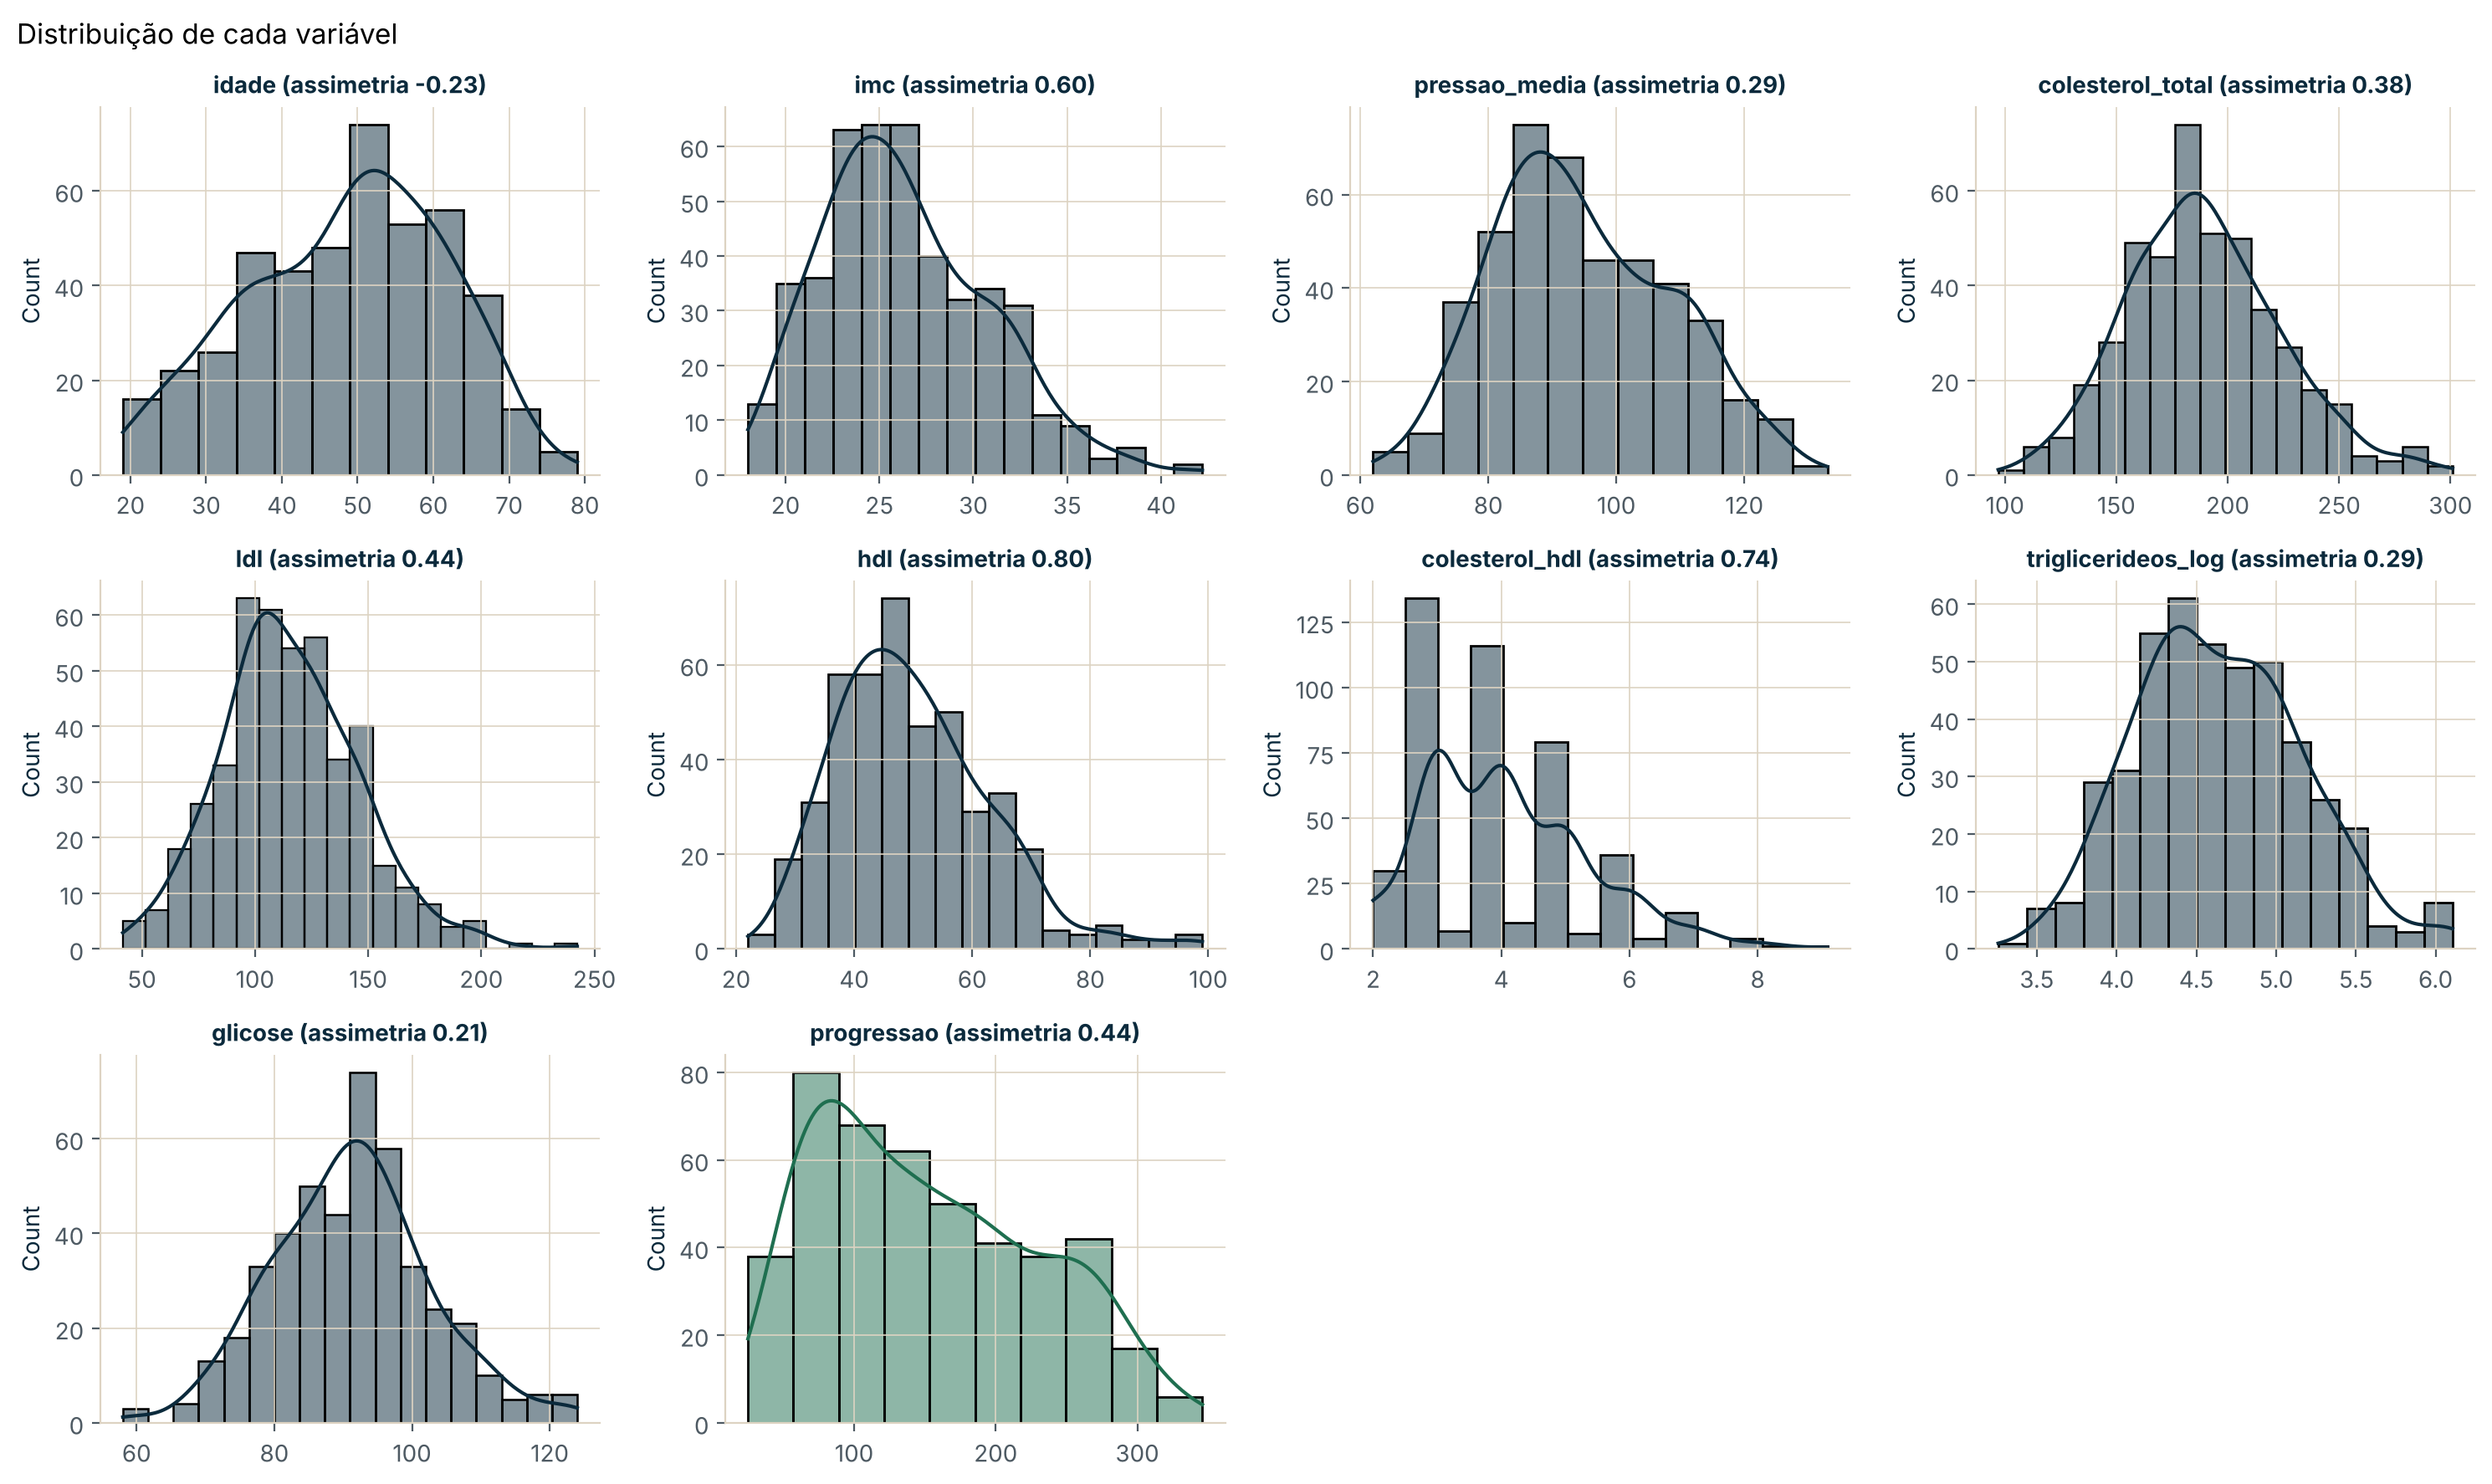

In [5]:
numericas = df.select_dtypes("number").columns.drop("progressao")

fig, eixos = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(eixos.flat, list(numericas) + ["progressao"]):
    sns.histplot(df[col], ax=ax, color=CORES["navy"] if col != "progressao" else CORES["verde"], kde=True)
    ax.set_title(f"{col} (assimetria {df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
for ax in eixos.flat[len(numericas) + 1:]:
    ax.set_visible(False)
fig.suptitle("Distribuição de cada variável", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(PASTA_IMAGENS / "01_distribuicoes.png")

O alvo (`progressao`) tem assimetria positiva: há mais doentes com progressão baixa.

## Valores extremos

imc                   3
colesterol_total      8
ldl                   7
hdl                   7
colesterol_hdl        2
triglicerideos_log    4
glicose               9
dtype: int64

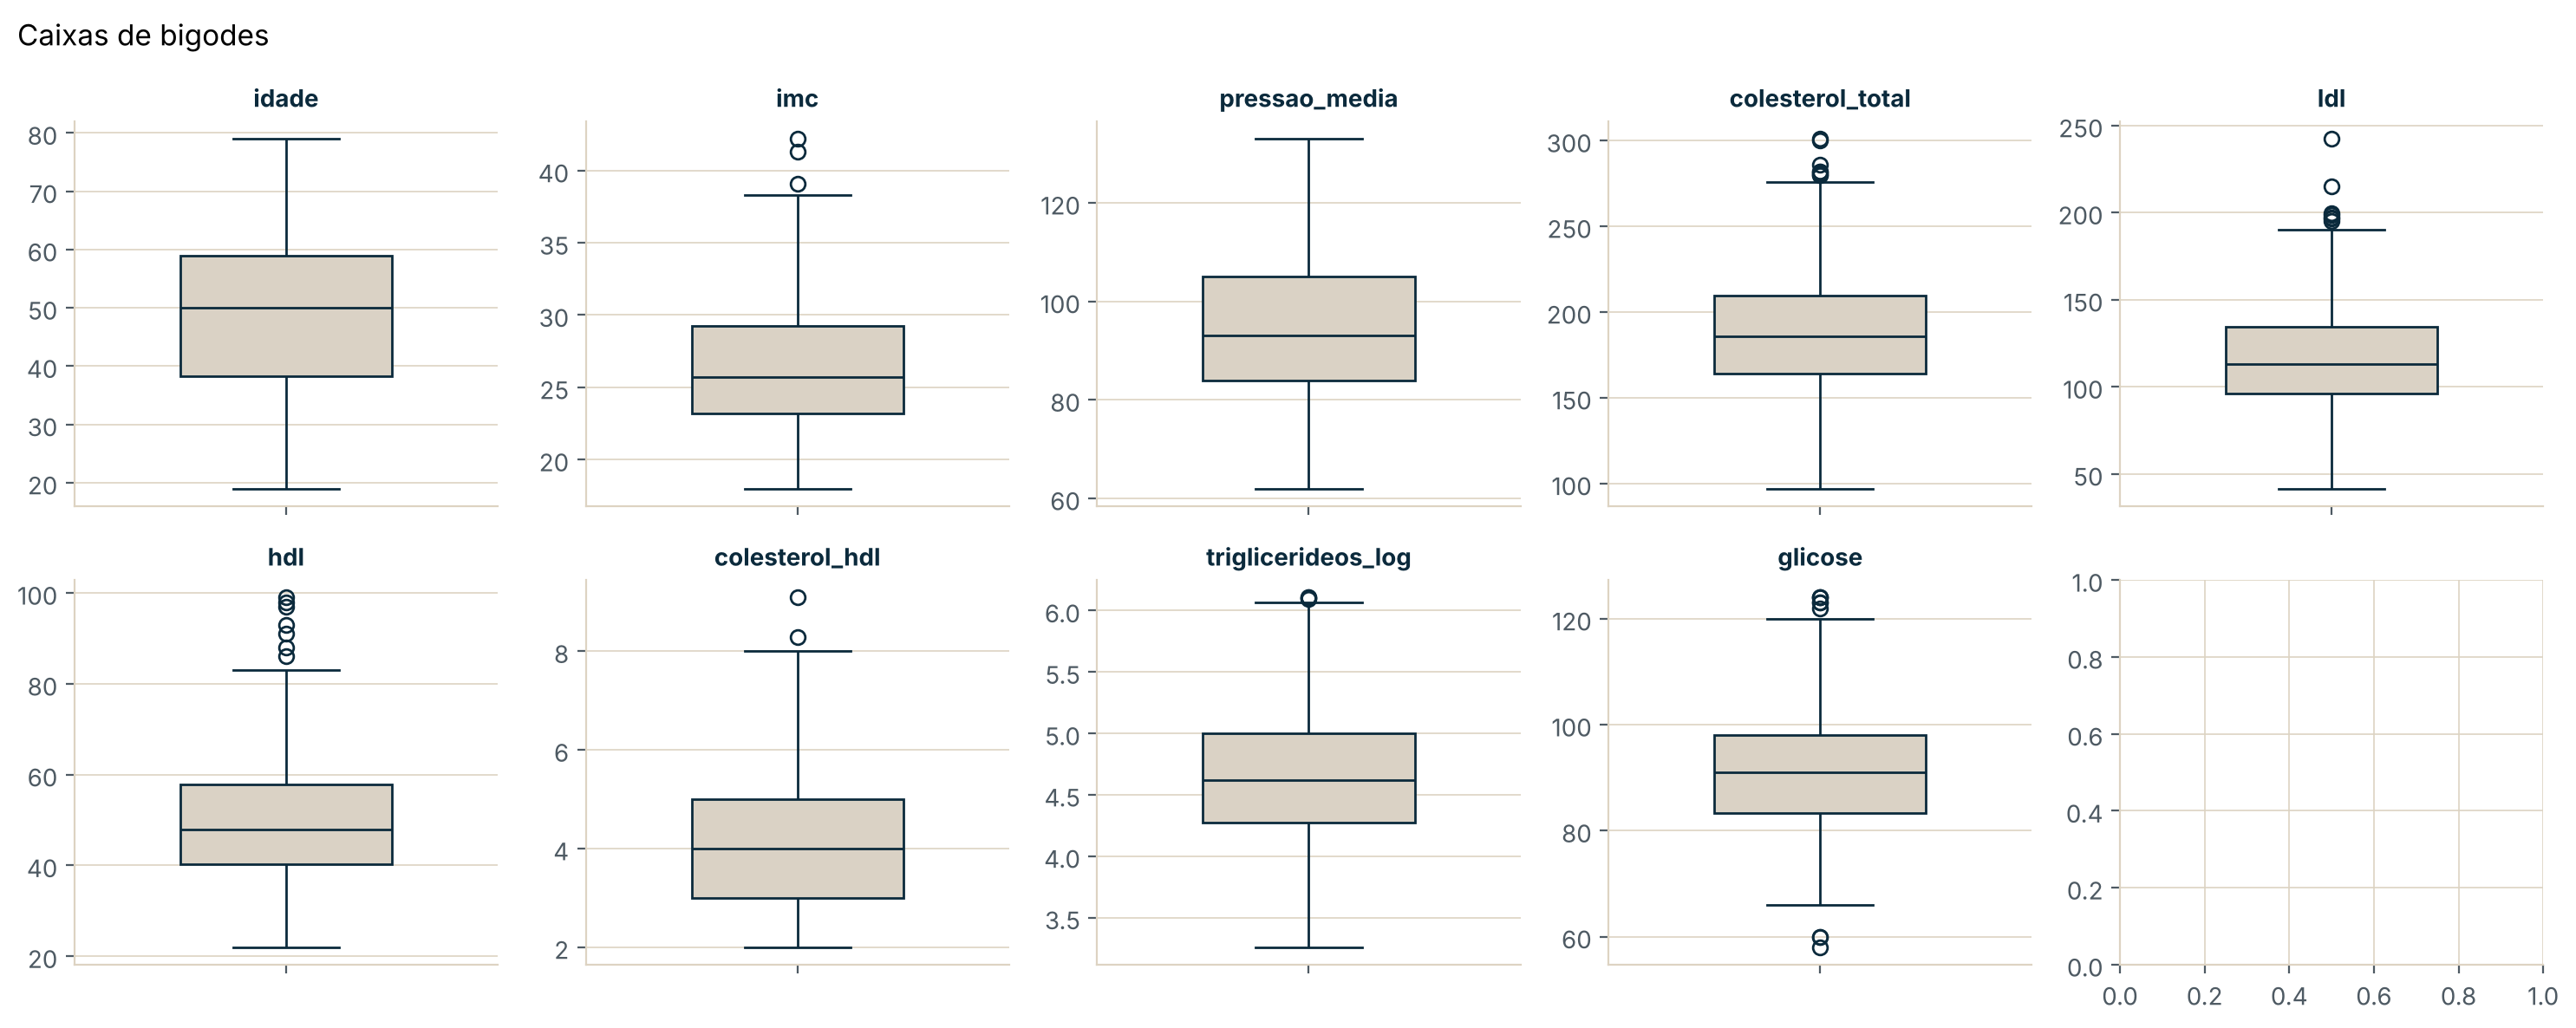

In [6]:
fig, eixos = plt.subplots(2, 5, figsize=(15, 6))
for ax, col in zip(eixos.flat, numericas):
    sns.boxplot(y=df[col], ax=ax, color=CORES["linha"], linecolor=CORES["navy"], width=0.5)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
fig.suptitle("Caixas de bigodes", x=0.01, ha="left")
fig.tight_layout()

q1, q3 = df[numericas].quantile([0.25, 0.75]).values
iqr = q3 - q1
fora = ((df[numericas] < q1 - 1.5 * iqr) | (df[numericas] > q3 + 1.5 * iqr)).sum()
fora[fora > 0]

Há poucos valores fora de 1,5 × IQR e todos plausíveis em análises clínicas. Ficam na base: retirar linhas numa base de 442 custaria mais do que ganharia.

## Correlações com o alvo

triglicerideos_log    0.59
imc                   0.56
colesterol_hdl        0.45
pressao_media         0.42
glicose               0.35
colesterol_total      0.23
idade                 0.20
ldl                   0.20
hdl                  -0.41
Name: progressao, dtype: float64

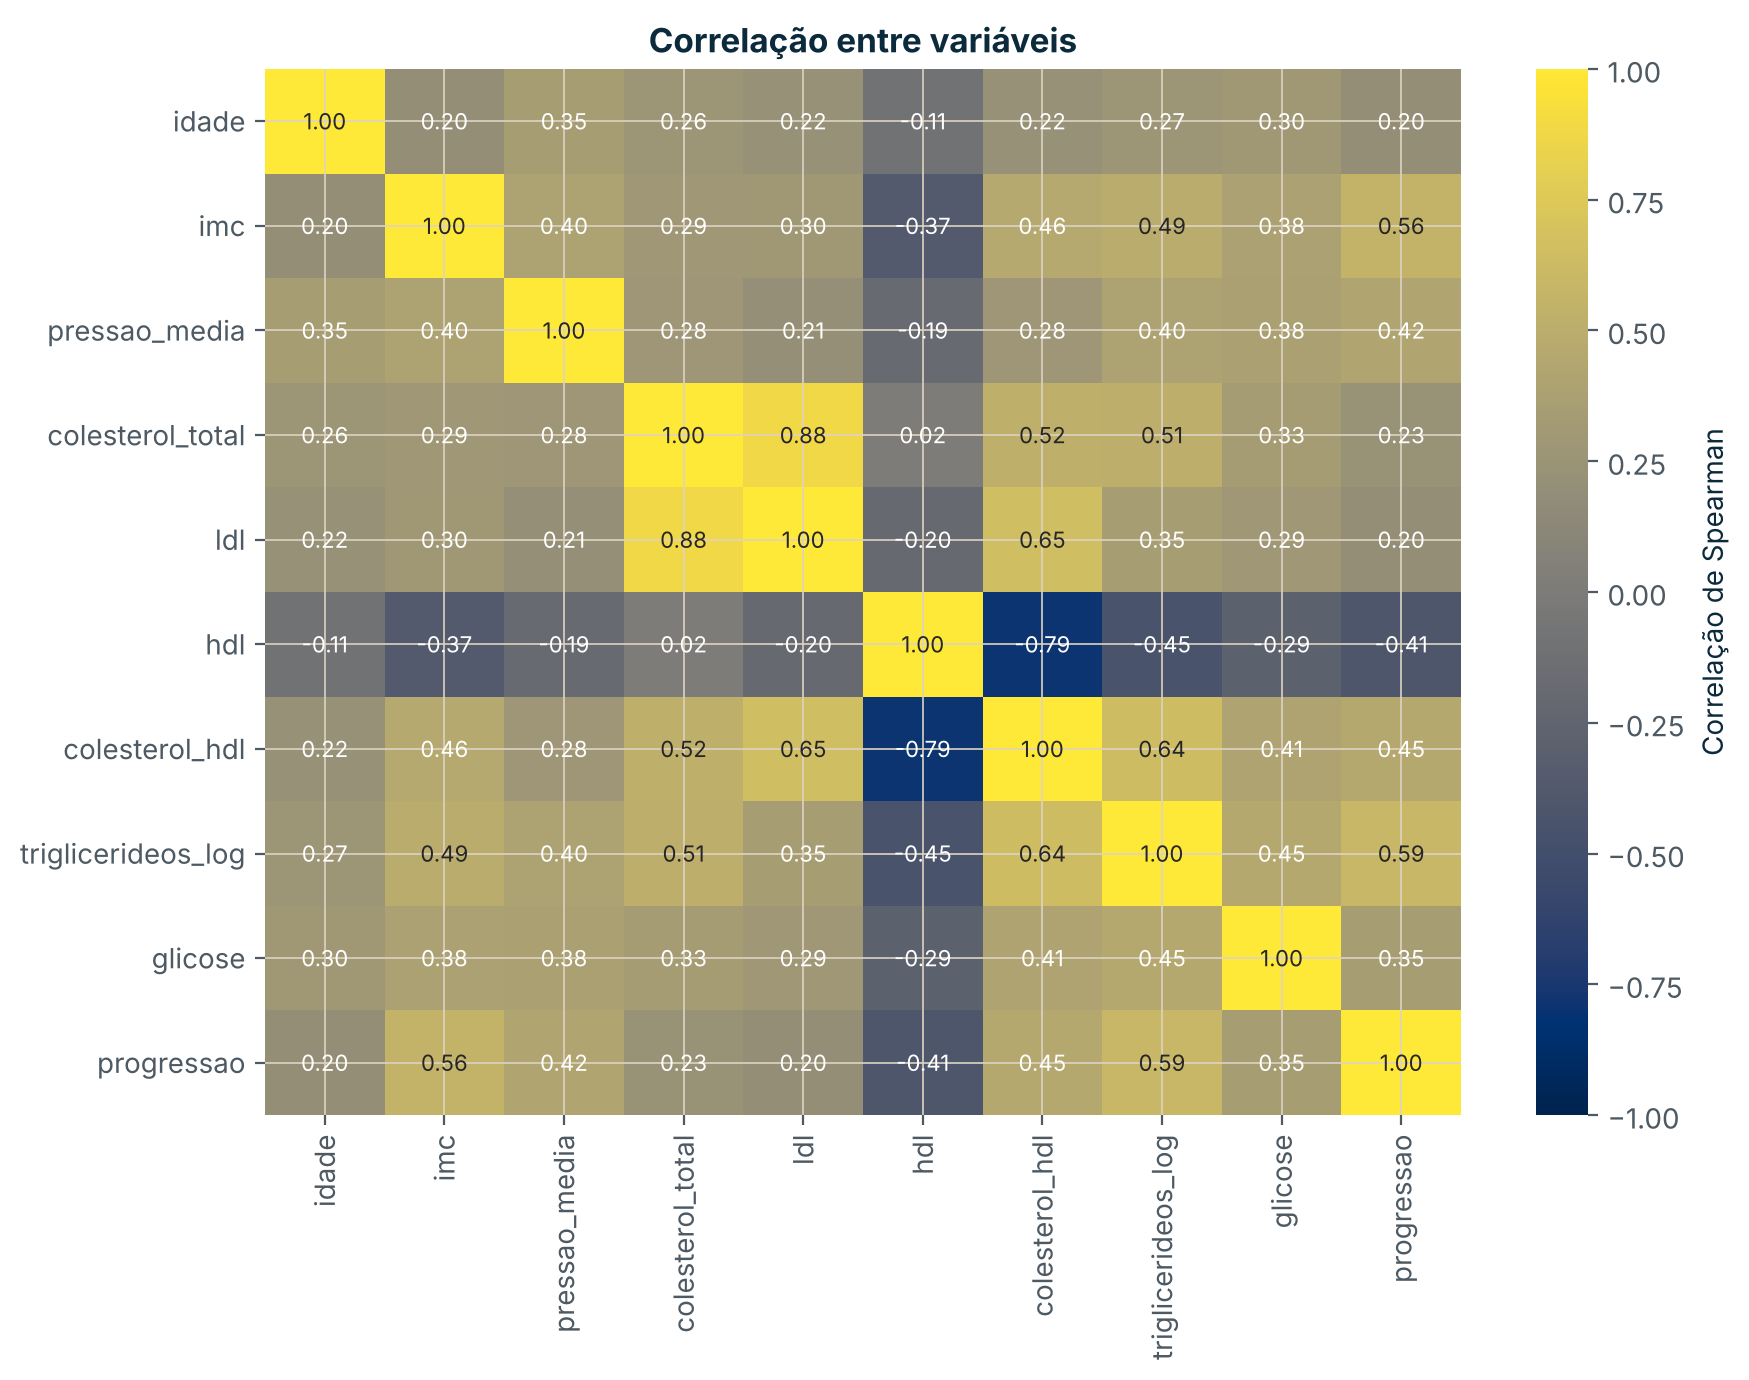

In [7]:
corr = df.drop(columns="sexo").corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="cividis", vmin=-1, vmax=1, ax=ax,
            annot_kws={"fontsize": 8}, cbar_kws={"label": "Correlação de Spearman"})
ax.set_title("Correlação entre variáveis")
fig.tight_layout()
fig.savefig(PASTA_IMAGENS / "01_correlacoes.png")

corr["progressao"].drop("progressao").sort_values(ascending=False).round(2)

**Leitura:**
- Os **triglicerídeos** (0,59) e o **IMC** (0,56) são as variáveis mais associadas à progressão; seguem-se o rácio **colesterol total/HDL** (0,45) e a **pressão média** (0,42).
- O **HDL** («colesterol bom») tem correlação negativa (−0,41): mais HDL, menor progressão.
- O **colesterol total** e o **LDL** estão muito correlacionados entre si (0,88); o mesmo se passa com `colesterol_hdl` e `hdl` (−0,79).

,count,mean,std,min,25%,50%,75%,max
sexo,,,,,,,,
1,235.0,149.0,75.9,25.0,85.5,140.0,200.0,346.0
2,207.0,155.7,78.5,39.0,88.0,141.0,220.5,341.0


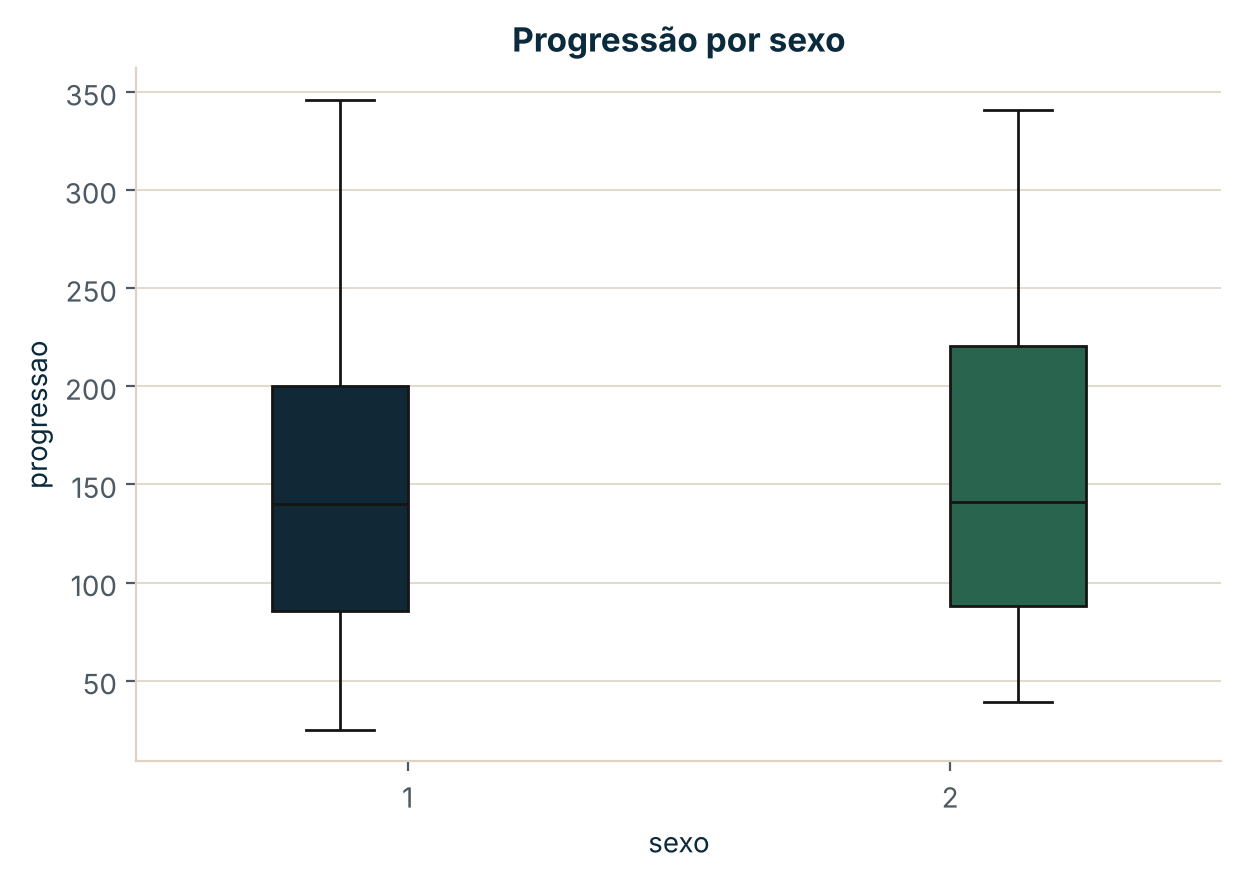

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x="sexo", y="progressao", hue="sexo", palette=PALETA[:2], legend=False, ax=ax, width=0.5)
ax.set_title("Progressão por sexo")
df.groupby("sexo", observed=True)["progressao"].describe().round(1)

A progressão é parecida nos dois grupos (medianas 140 e 141). O sexo entra no modelo como variável categórica.

## Exportar a base tratada

In [9]:
df.to_csv(DADOS_TRATADOS, index=False)
print(DADOS_TRATADOS.name, df.shape)

diabetes_tratado.csv (442, 11)
